# 英日機械翻訳の品質推定

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb)

書籍 第1章の評価尺度（練習問題 2）と、第2章の文章の品質推定（2-3、練習問題 3・4）に対応します。

ここでは品質推定 (Quality Estimation; QE) の演習をします。品質推定は、参照訳（人手の正解訳）を使わずに、原文と機械翻訳の出力だけから翻訳の品質を推定するタスクです。

下では GPU を用いて深層学習モデルのファインチューニングを行うので、[ランタイム] → [ランタイムのタイプを変更] から [ハードウェア アクセラレータ] を `GPU`（T4 など）にしておいてください（`CPU` のままだと10倍以上遅いです）。

In [1]:
import torch

if torch.cuda.is_available():
    print("使用可能な GPU:", torch.cuda.get_device_name(0))
else:
    print("警告: GPU が見つかりません（CPU で実行されます）。Colab の「ランタイム」→「ランタイムのタイプを変更」から GPU を選択してください。")

使用可能な GPU: Tesla T4


## データの準備

Workshop on Machine Translation (WMT) という機械翻訳のトップ国際会議では、毎年品質推定の共通タスクが開かれています。ここでは、[WMT21](https://www.statmt.org/wmt21/quality-estimation-task.html) と [WMT22](https://wmt-qe-task.github.io/wmt-qe-2022/) の品質推定タスクで公開された英日翻訳のデータを使います。英語の原文、その機械翻訳（日本語）、そして人手で付けた翻訳の品質のスコア (direct assessment; DA) がそれぞれ1,000文ずつあります。スコアは評価者ごとに標準化（z スコア化）されていて、大きいほど良い翻訳です。

WMT21 のデータ ([MLQE-PE](https://github.com/sheffieldnlp/mlqe-pe)) を訓練・開発データに、WMT22 のデータをテストデータに使います。

In [2]:
!mkdir -p qedata/wmt22
!curl -fsSL https://github.com/sheffieldnlp/mlqe-pe/raw/master/data/test21_goldlabels/zero-shot/en-ja-test21.tar.gz | tar xz -C qedata
!for f in test.2022.src test.2022.mt test.2022.en-ja.da_score; do curl -fsSL -o qedata/wmt22/$f https://raw.githubusercontent.com/WMT-QE-Task/wmt-qe-2022-data/main/test_data-gold_labels/task1_da/en-ja/$f; done
!wc -l qedata/en-ja-test21/test21.src qedata/en-ja-test21/test21.mt qedata/en-ja-test21/goldlabels/test21.da qedata/wmt22/*

  1000 qedata/en-ja-test21/test21.src
  1000 qedata/en-ja-test21/test21.mt
  1000 qedata/en-ja-test21/goldlabels/test21.da
  1000 qedata/wmt22/test.2022.en-ja.da_score
  1000 qedata/wmt22/test.2022.mt
  1000 qedata/wmt22/test.2022.src
  6000 total


`pandas` の `DataFrame` に読み込みます。`src` が原文、`mt` が機械翻訳、`label` が人手評価のスコアです。WMT21 のデータのうち200文を開発データにし、残りの800文を訓練データにします。実験のたびに結果が変わらないようにシードを固定します。

In [3]:
import pandas as pd

def read(directory, src, mt, score):
    lines = lambda f: [l.rstrip("\n") for l in open(f"{directory}/{f}", encoding="utf-8")]
    return pd.DataFrame({"src": lines(src), "mt": lines(mt), "label": [float(x) for x in lines(score)]})

wmt21 = read("qedata/en-ja-test21", "test21.src", "test21.mt", "goldlabels/test21.da")
df_test = read("qedata/wmt22", "test.2022.src", "test.2022.mt", "test.2022.en-ja.da_score")
df_valid = wmt21.sample(n=200, random_state=42)
df_train = wmt21.drop(index=df_valid.index)
print(len(df_train), len(df_valid), len(df_test))
df_test.head()

800 200 1000


,src,mt,label
0,The treated water is then relayed by gravity a...,その後、処理された水は重力とポンプによって31のサービスリザーバにリレーされ、顧客に伝達されます。,0.701980
1,A Canadian edition of the first issue appeared...,第1号のカナダ版は、米国版と同じ内容のトロントのより良い出版物から登場した。,0.088665
2,The album was produced by the astar arts recor...,このアルバムは、スター・アーツ・レコーディングとイギリスのキャディガン・オブ・シアターのMo...,0.155987
3,A substantial bibliography about papunya art a...,オーストラリア国立博物館からパプニャの芸術と芸術家に関する重要な文献が入手可能である。,0.716523
4,Donald B. Lacey display garden - unusual and c...,Donald B. Laceyディスプレイガーデン - 珍しいとカラフルな年間、熱帯、ハーブ...,-0.303177


スコアの分布も見てみましょう。良い翻訳（スコアが大きい）が多く、ひどい翻訳（スコアが小さい）が少ないことがわかります。

In [4]:
df_train["label"].describe()

,label
count,800.000000
mean,0.037554
std,0.768581
min,-4.814519
25%,-0.383048
50%,0.072487
75%,0.515437
max,2.007649


## モデルの訓練

XLM-RoBERTa (XLM-R) という多言語の事前学習モデルを、原文と機械翻訳のペアを入力としてスコアを予測する回帰モデルとしてファインチューニングします。XLM-R はクロスリンガルな事前学習をすることで、多言語の文脈付き単語埋め込みを学習したモデルです。これは、WMT20 の品質推定タスクで1位だった [TransQuest](https://github.com/TharinduDR/TransQuest) の MonoTransQuest と同じ構成です（TransQuest は2021年以降更新されておらず、現在の Transformers では動かないので、ここでは Transformers の `Trainer` を直接使います）。

large モデルは GPU のメモリを大量に消費し、訓練にも時間がかかるので、ここでは base モデルを使います。

In [5]:
!pip install -q datasets

In [6]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, set_seed

model_name = "xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def encode(df):
    # 原文と機械翻訳をペアとしてモデルに入力する
    dataset = Dataset.from_pandas(df.reset_index(drop=True))
    return dataset.map(lambda e: tokenizer(e["src"], e["mt"], truncation=True, max_length=256),
                       batched=True, remove_columns=["src", "mt"])

train_dataset, valid_dataset, test_dataset = encode(df_train), encode(df_valid), encode(df_test)

# num_labels=1 にすると、スコアを予測する回帰モデルになる
set_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)

### 評価尺度

推定したスコアと人手評価のスコアの相関で評価します。評価尺度の評価になるので、区別する場合はメタ評価と呼ばれます。

- Pearson の相関係数は、推定したスコアの値そのものが人手評価と線形の関係にあるかを測ります。
- Spearman の順位相関係数は、推定スコアと人手評価をそれぞれ順位に変換したうえで、その順位の相関を測ります。Kendall の順位相関係数 (Kendall's tau) は、文を2つずつ比較し、スコアの大小関係が一致するペアと逆転するペアの数の差を正規化します。人手評価で高いスコアを得た訳文をモデルも上位に並べるほど、順位相関は高くなります。

[WMT22 の英日文単位品質推定](https://aclanthology.org/2022.wmt-1.3/) (Task 1 Direct Assessment) では、Spearman の順位相関係数が公式順位の主指標です。この演習では、従来の Kendall に加え、開発データの Spearman が最も高いエポックも選びます。選んだ2つのモデルを同じ WMT22 のテストデータで比べます。

なお、Kendall's tau や Spearman の順位相関係数などの順位評価尺度のスクラッチ実装については、`ch2_ranking.ipynb` も参照してください。

In [7]:
from scipy.stats import pearsonr, spearmanr, kendalltau

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = predictions.squeeze()
    return {"kendall": kendalltau(predictions, labels)[0],
            "pearson": pearsonr(predictions, labels)[0],
            "spearman": spearmanr(predictions, labels)[0]}

### ハイパーパラメータ

学習率は1e-5、エポック数は10にします。2026年10月に、XLM-R の base と large、学習率を変えて試したところ、base では学習率1e-5 が一番良く、学習率を大きくすると悪くなりました。T4 で3分ほどで訓練が終わります。

In [8]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

training_args = TrainingArguments(output_dir="qe_model",
                                  learning_rate=1e-5,
                                  num_train_epochs=10,
                                  per_device_train_batch_size=16,
                                  per_device_eval_batch_size=64,
                                  warmup_steps=0.1,  # 最初の10%のステップで学習率を徐々に上げる
                                  weight_decay=0.01,
                                  fp16=torch.cuda.is_available(),
                                  eval_strategy="epoch",
                                  save_strategy="epoch",  # Kendall と Spearman の両方で選べるよう各エポックを保存する
                                  save_only_model=True,  # オプティマイザの状態は保存しない（保存に時間がかかるため）
                                  logging_strategy="epoch",
                                  load_best_model_at_end=True,
                                  metric_for_best_model="kendall",
                                  seed=42,
                                  report_to="none",  # Weights & Biases などへのログ送信をしない
                                  )

trainer = Trainer(model=model,
                  args=training_args,
                  train_dataset=train_dataset,
                  eval_dataset=valid_dataset,
                  data_collator=DataCollatorWithPadding(tokenizer),
                  compute_metrics=compute_metrics)
trainer.train()

Epoch,Training Loss,Validation Loss,Kendall,Pearson,Spearman
1,0.601083,0.728239,0.022589,0.058847,0.032568
2,0.595197,0.725211,0.126134,0.208275,0.187941
3,0.580395,0.684209,0.200333,0.279027,0.293551
4,0.564596,0.696249,0.171179,0.253773,0.248450
5,0.519332,0.736608,0.078920,0.163936,0.117364
6,0.469433,0.719444,0.186397,0.306522,0.269823
7,0.423913,0.688633,0.166197,0.291923,0.238679
8,0.388593,0.740824,0.186946,0.295869,0.271291
9,0.351819,0.800768,0.130862,0.245041,0.188694
10,0.324052,0.774046,0.135738,0.255951,0.197194


TrainOutput(global_step=500, training_loss=0.4818413734436035, metrics={'train_runtime': 185.9365, 'train_samples_per_second': 43.025, 'train_steps_per_second': 2.689, 'total_flos': 366049969125120.0, 'train_loss': 0.4818413734436035, 'epoch': 10.0})

### 開発データでのチェックポイント選択

従来どおり、`Trainer` は開発データ上の Kendall が最も高いチェックポイントを訓練終了時に読み込みます。毎エポックの保存と評価を行い、同じ訓練の評価ログから Spearman が最も高いチェックポイントも選びます。同点なら先に評価したものを選びます。テストデータは選択に使いません。

各エポックでモデルの重みを保存するため、チェックポイント用のディスク容量が必要です。

In [9]:
from pathlib import Path

dev_results = pd.DataFrame(
    [row for row in trainer.state.log_history if "eval_spearman" in row]
).set_index("step")
kendall_step = trainer.state.best_global_step
spearman_step = int(dev_results["eval_spearman"].idxmax())
spearman_checkpoint = Path(training_args.output_dir) / f"checkpoint-{spearman_step}"

pd.DataFrame([
    {
        "選択基準": criterion,
        "ステップ": step,
        "エポック": int(dev_results.loc[step, "epoch"]),
        "開発 Kendall": dev_results.loc[step, "eval_kendall"],
        "開発 Spearman": dev_results.loc[step, "eval_spearman"],
    }
    for criterion, step in (("Kendall", kendall_step), ("Spearman", spearman_step))
]).round(4)

,選択基準,ステップ,エポック,開発 Kendall,開発 Spearman
0,Kendall,150,3,0.2003,0.2936
1,Spearman,150,3,0.2003,0.2936


## テストデータで評価

訓練したモデルを WMT22 のテストデータで評価してみましょう。

2026年10月に試したときは、Kendall's tau が 0.16～0.17、Pearson の相関係数が0.23～0.26程度でした（実行のたびに結果は少し変わります）。参考までに、large モデル（`xlm-roberta-large`、学習率5e-6）では Kendall's tau が0.19、Pearson の相関係数が0.30でした。

In [10]:
pred = trainer.predict(test_dataset)
print(pred.metrics)
df_test["prediction"] = pred.predictions.squeeze()
df_test.sort_values("prediction").head(10)

{'test_loss': 0.49096399545669556, 'test_kendall': 0.15616063936484353, 'test_pearson': 0.23928900063037872, 'test_spearman': 0.2334131921318413, 'test_runtime': 1.3023, 'test_samples_per_second': 767.874, 'test_steps_per_second': 12.286}


,src,mt,label,prediction
54,"Two - disc cd featuring Slade alive!, Slayed?,...","スレードが生きている!, スレード?, 古い新しい借りて青と炎の中でスレード.",-0.574524,-0.501953
626,"Facundo as soup duck, a professional rapping d...","スープダックとしてファカンド, プロのラッピングダック. 彼はアメリカのラッパースヌープドッ...",0.009804,-0.473633
499,"Depending on the lineage, kusanku is the secon...",家系によっては、石神龍の禅月達を含んだ2つのカタの2番目のカタである。,-0.296306,-0.413330
928,A loud murmur with a thrill. The murmur is so ...,スリルを伴う大声のmurmur. それは耳のステトスコープの縁だけが胸に触れて聞こえるほど大...,-0.824767,-0.334229
868,"Lydia:With one paw, trying the edges of the wi...",Lydia:ひとつの爪で、冬の池の端を試し、その水が固体であることを発見し、彼は進み、爪が滑...,0.112311,-0.322998
698,Division shown in bold when it changes due to ...,昇進や降格により変更される場合のディビジョンを大胆に示す. トップスコアは、クラブの記録を設...,-2.361270,-0.321289
913,"After The Olympics, Zheng entered the us open....","オリンピック後, 鄭は私たちのオープンに入力しました. 彼女は第3ラウンドに進み、2番目の ...",-0.963532,-0.302734
307,Lower Camp refers to the part of camp downhill...,下のキャンプは、キャンプを通るメインロードであるモリス牧場から下り坂の部分を指し、プログラム...,0.465047,-0.299805
238,Also in the Silver King Creek Watershed are th...,シルバーキングクリーク流域には、シエラ・ネバダのイエロー脚のカエル、山のイエロー脚のカエル、...,-0.120600,-0.296143
561,A sling is a projectile weapon typically used ...,スリングは通常、石、粘土または鉛の「スリング - 弾丸」のようなぼやけた弾丸を投げるために使...,-0.053278,-0.271973


推定したスコアが低い（品質が悪いと推定した）翻訳を上に表示しています。人手評価のスコア (`label`) と比べてみましょう。

上の表は従来の Kendall で選んだモデルの出力です。続いて Spearman で選んだモデルでも、同じテスト文を同じ順序で推定します。両基準で同じチェックポイントが選ばれた場合は、先ほどの予測を使います。

In [11]:
if spearman_step == kendall_step:
    pred_spearman = pred
else:
    spearman_trainer = Trainer(
        model=AutoModelForSequenceClassification.from_pretrained(spearman_checkpoint),
        args=training_args,
        eval_dataset=valid_dataset,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
    )
    pred_spearman = spearman_trainer.predict(test_dataset)
    del spearman_trainer

df_test["prediction_spearman"] = pred_spearman.predictions.squeeze()

## 既存の品質推定モデルとの比較

[COMET](https://github.com/Unbabel/COMET) は、WMT で広く使われている機械翻訳の自動評価のためのツールです。COMET には、参照訳を使わずに品質推定ができるモデルもあります。ここでは、WMT20 の品質推定のためのモデル (`wmt20-comet-qe-da`) を、ファインチューニングせずにそのまま使ってみます。このモデルは、WMT の大量の人手評価のデータで訓練されています（英日のデータは含まれていません）。

COMET を Google Colab にそのままインストールすると、あらかじめ入っているライブラリのバージョンが変わってしまうので、[uv](https://docs.astral.sh/uv/) という高速なパッケージ管理ツールを使って別の仮想環境を作り、そこにインストールします。数分かかります。

In [12]:
!pip install -q uv
!uv venv -q --clear -p 3.12 /content/comet-env
!uv pip install -q -p /content/comet-env unbabel-comet "setuptools<70"

仮想環境の Python で COMET を動かすために、原文と機械翻訳をファイルに書き出して、`comet-score` というコマンドで推定します。原文を `-s`、機械翻訳を `-t` で指定し、参照訳 (`-r`) は指定しません。CPU ランタイムで実行する場合は、[COMET の実行手順](https://github.com/Unbabel/COMET#scoring-mt-outputs)に従って `comet-score` のオプションに `--gpus 0` を追加してください。

In [13]:
open("test.src", "w", encoding="utf-8").write("\n".join(df_test["src"]) + "\n")
open("test.mt", "w", encoding="utf-8").write("\n".join(df_test["mt"]) + "\n")
!/content/comet-env/bin/comet-score -s test.src -t test.mt --model Unbabel/wmt20-comet-qe-da --quiet > comet.txt
!head -n 3 comet.txt

test.mt	Segment 0	score: 0.4751
test.mt	Segment 1	score: 0.0187
test.mt	Segment 2	score: 0.1252


In [14]:
with open("comet.txt", encoding="utf-8") as f:
    comet = [float(l.split("score:")[-1]) for l in f if "Segment" in l]
assert len(comet) == len(df_test), f"件数不一致: {len(comet)} != {len(df_test)}"
df_test["comet"] = comet
models = [
    ("XLM-R（開発 Kendall で選択）", "prediction"),
    ("XLM-R（開発 Spearman で選択）", "prediction_spearman"),
    ("COMET-QE", "comet"),
]
pd.DataFrame([
    {
        "モデル": name,
        **compute_metrics((df_test[column].to_numpy(), df_test["label"].to_numpy())),
    }
    for name, column in models
])[["モデル", "spearman", "kendall", "pearson"]].round(4)

,モデル,spearman,kendall,pearson
0,XLM-R（開発 Kendall で選択）,0.2334,0.1562,0.2393
1,XLM-R（開発 Spearman で選択）,0.2334,0.1562,0.2393
2,COMET-QE,0.2942,0.1985,0.2973


2026年10月に試したときは、COMET-QE は Kendall's tau が0.20、Pearson の相関係数が0.30で、800文でファインチューニングした XLM-R の base モデルより高い相関でした。大量の人手評価のデータで訓練されたモデルは、英日のデータで訓練していなくても、ある程度品質を推定できることがわかります。COMET-QE をさらに英日のデータでファインチューニングしたり、訓練データを増やしたりすると、もっと良くなるかもしれません。

## 散布図と誤り分析

相関係数だけでなく、人手評価のスコア (`label`) と各モデルの推定スコア（XLM-R の `prediction`、COMET-QE の `comet`）の散布図を描いて傾向を確認しましょう。さらに、人手評価と推定スコアの乖離が特に大きい事例（見た目は流暢なのに誤訳を含むために過大評価された翻訳や、逆に過小評価された翻訳）を抽出して観察します。

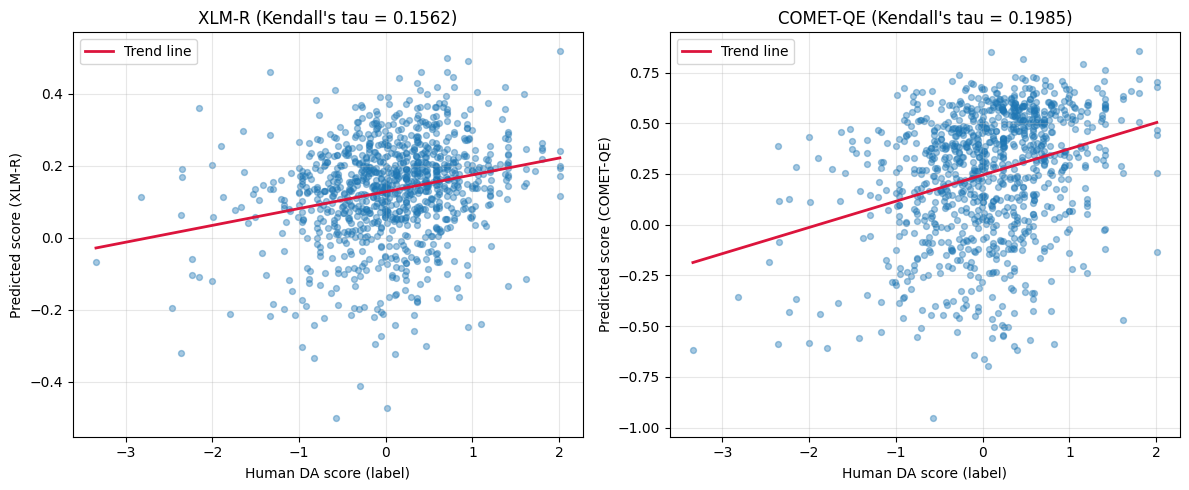

In [15]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
models = [("prediction", "XLM-R"), ("comet", "COMET-QE")]

for ax, (col, title) in zip(axes, models):
    x = df_test["label"].to_numpy()
    y = df_test[col].to_numpy()
    tau = kendalltau(y, x)[0]
    ax.scatter(x, y, alpha=0.4, s=18)
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, slope * xs + intercept, color="crimson", linewidth=2, label="Trend line")
    ax.set_xlabel("Human DA score (label)")
    ax.set_ylabel(f"Predicted score ({title})")
    ax.set_title(f"{title} (Kendall's tau = {tau:.4f})")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# スケールの違いを揃えるため z スコア化して人手評価との乖離（COMET-QE - 人手評価）を計算する
def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

analysis_df = df_test.copy()
analysis_df["diff_z"] = (zscore(analysis_df["comet"]) - zscore(analysis_df["label"])).round(3)
cols = ["src", "mt", "label", "prediction", "comet", "diff_z"]

print("【過大評価された例】人手評価は低いのに高スコアと推定された翻訳（流暢な誤訳・情報抜けなど）:")
display(analysis_df.sort_values("diff_z", ascending=False)[cols].head(5))

print("【過小評価された例】人手評価は高いのに低スコアと推定された翻訳:")
display(analysis_df.sort_values("diff_z", ascending=True)[cols].head(5))

【過大評価された例】人手評価は低いのに高スコアと推定された翻訳（流暢な誤訳・情報抜けなど）:


,src,mt,label,prediction,comet,diff_z
607,Yokote is located in southeast corner of Akita...,横手県は秋田県の東南角に位置し、東には大宇山、東には岩手県がある。,-2.361270,0.063782,0.3855,3.807
207,There are smoking cessation policy initiatives...,アメリカ合衆国政府は、連邦、州、地方レベルで禁煙政策のイニシアチブがある。,-2.005821,0.202026,0.4341,3.468
242,Mcfly - Guitarist / vocalist / songwriter Tom ...,トム・フレッチャー(Tom Fletcher) - ギタリスト・ボーカル・ソングライター。,-2.152005,0.359863,0.2844,3.192
596,The ho - ho - kus brook flows through the cent...,ホーホークス川は、町の中心部をほぼ南向きに流れています。,-1.630759,0.183350,0.4573,3.020
440,March 11-gunmen in Kabul kill Swedish Radio Fo...,3月11日 - カブールでスウェーデンのラジオ外国記者ニルス・ホーナーが殺害。,-1.901189,0.255127,0.3262,2.977


【過小評価された例】人手評価は高いのに低スコアと推定された翻訳:


,src,mt,label,prediction,comet,diff_z
874,"Contents include "" Black Orchids "" and "" cordi...","内容には "" 黒い蘭 "" と "" 心から死に会うために招待されています "".",1.622678,-0.113464,-0.4719,-4.490
277,The leading apologetic organisation foundation...,古代研究とモルモン研究(農学)のための主要な謝罪組織財団が設立されています。,2.007649,0.172485,-0.1360,-3.949
416,"According to cassanelli, ""the geledi and WA ' ...","キャッサネリによると、""ゲレディとWA ' SILを駆動するためにダン同盟' はafgoyか...",0.819177,-0.140747,-0.5864,-3.738
857,"The b - side ""Acquiesce"" was released as part ...","b - サイド ""Acquiesce"" は、彼らのコンピレーションアルバムのプロモーションで...",0.546627,-0.018143,-0.5684,-3.301
993,"Garner, rod. The Bideford, westward ho! & Appl...","ガーナー, ロッド. ビードフォード, 西へホー! & Appledore 鉄道. パブ. ...",0.400646,0.083191,-0.6172,-3.254
